In [6]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

In [7]:
# 데이터 불러오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [8]:
fish.info(0)

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Species   159 non-null    str    
 1   Weight    159 non-null    float64
 2   Length    159 non-null    float64
 3   Diagonal  159 non-null    float64
 4   Height    159 non-null    float64
 5   Width     159 non-null    float64
dtypes: float64(5), str(1)
memory usage: 7.6 KB


In [9]:
fish.describe()

,Weight,Length,Diagonal,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,28.415723,31.227044,8.970994,4.417486
std,357.978317,10.716328,11.610246,4.286208,1.685804
min,0.000000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,63.400000,68.000000,18.957000,8.142000


In [10]:
fish.columns

Index(['Species', 'Weight', 'Length', 'Diagonal', 'Height', 'Width'], dtype='str')

In [11]:
# 데이터 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [12]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [13]:
cc = [0.0001,0.001,0.1,1,10,20,100]
train_score = []
test_score = []
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

In [14]:
train_score

[0.33613445378151263,
 0.33613445378151263,
 0.7226890756302521,
 0.8151260504201681,
 0.8739495798319328,
 0.9243697478991597,
 0.9831932773109243]

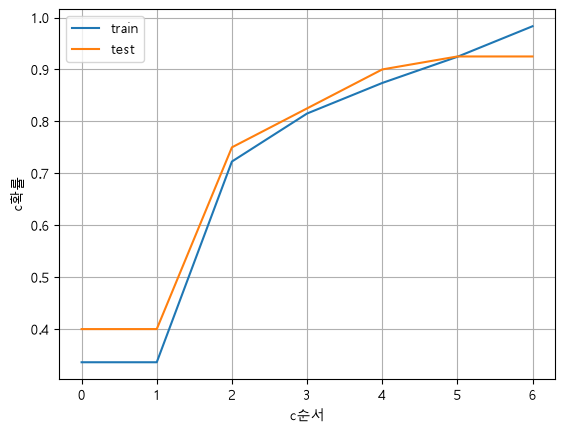

In [15]:
list1 = list(range(7))
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('c순서')
plt.ylabel('c확률')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [16]:
print("train정확도 : ",lr.score(train_scaled,train_label))
print("test정확도 : ",lr.score(test_scaled,test_label))

train정확도 :  0.9831932773109243
test정확도 :  0.925


In [17]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [19]:
# 실제입력받아 예측하시오.
predict = lr.predict(test_scaled[:1])
print('분류생선 : ',predict)
proba = lr.predict_proba(test_scaled[:1])

# if문을 넣어서 확인
if predict[0] == 'Bream':
    result = proba[0][0]
elif predict[0] == 'Parkki':
    result = proba[0][1]    
elif predict[0] == 'Perch':
    result = proba[0][2]    
elif predict[0] == 'Pike':
    result = proba[0][3]    
elif predict[0] == 'Roach':
    result = proba[0][4]    
elif predict[0] == 'Smelt':
    result = proba[0][5]    
elif predict[0] == 'Whitefish':
    result = proba[0][6]    

print('확률 : ',result)

분류생선 :  ['Roach']
확률 :  0.9036352114880849
